# Secular approximation of Hamiltonian terms: six examples

All examples use 38 GHz, 293 K, and Gaussian/Lorentzian linewidths only. Each case shows the secularity diagnostic and the full/secular CW spectra.

In [1]:
import os
import sys
import importlib.metadata
from pathlib import Path

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..", "..", "..", "..")))

import torch
import numpy as np
import matplotlib.pyplot as plt
import mars


dtype = torch.float64
eps = 0.1
freq = 38e9
temperature = 293
sweep_mesh = (10, 10)
spectrum_mesh = (25, 25)
n_field_points = 1500

## Method

The criterion is the relative norm of the terms removed from the static Hamiltonian:

$$\eta_H(B_0)=\frac{\|\Delta F+B_0\Delta G_z\|_F}{\|F+B_0G_z\|_F},\qquad \Delta A=A-A_{\rm sec}.$$

We mark $\eta_H>\varepsilon$ as a heuristic breakdown point, not a strict spectral or relaxation limit. $B_0$ is the estimated central field.

In [2]:
### HERE IS plotting ### 
FIGURE_WIDTH_MM = 165
FIGURE_HEIGHT_MM = 62
FONT_SIZE = 10
OUTPUT_DIR = Path("eps_figures")
OUTPUT_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "font.size": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "axes.titlesize": FONT_SIZE,
    "xtick.labelsize": FONT_SIZE,
    "ytick.labelsize": FONT_SIZE,
    "legend.fontsize": FONT_SIZE,
    "ps.fonttype": 42,
    "pdf.fonttype": 42,
    "font.family": "DejaVu Sans",
    "text.usetex": False,
})

In [3]:
def _mm_to_inch(value_mm):
    return value_mm / 25.4


def _slugify(text):
    return "".join(ch.lower() if ch.isalnum() else "_" for ch in text).strip("_")


def _set_bold_ticklabels(ax, x=True, y=True):
    if x:
        for label in ax.get_xticklabels():
            label.set_fontweight("bold")
    if y:
        for label in ax.get_yticklabels():
            label.set_fontweight("bold")


def _style_criterion_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.yaxis.set_ticks_position("left")
    ax.xaxis.set_ticks_position("bottom")
    _set_bold_ticklabels(ax, x=True, y=True)


def _style_spectrum_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.yaxis.set_visible(False)
    ax.xaxis.set_ticks_position("bottom")
    _set_bold_ticklabels(ax, x=True, y=False)


In [4]:
def run_case(title, make_sample, values, g_mean, fields, xlabel, units=1.0, file_tag=None):
    """Sweep one parameter; plot the deviation and two CW spectra."""
    b0 = float(mars.constants.unit_converter(freq / g_mean, "Hz_to_T_e"))
    with torch.no_grad():
        reports = [
            make_sample(float(p), sweep_mesh)._check_secularity(field=b0, secular_relative_tolerance=eps, warn=False)
            for p in values
        ]
    print(b0)

    deviations = np.array([report["H_ratio"] for report in reports])
    bad = np.flatnonzero([not report["valid"] for report in reports])
    k = int(bad[0]) if len(bad) else len(values) - 1
    p = float(values[k])

    if len(bad) and k:
        print(f"{title}: first failure in [{values[k-1]/units:.3g}, {p/units:.3g}].")
    elif len(bad):
        print(f"{title}: fails at the sweep start ({p/units:.3g}).")
    else:
        print(f"{title}: no failure; spectrum at endpoint {p/units:.3g}.")
    
    computational_details = mars.spectra_manager.ComputationalDetails(secular_relative_tolerance=eps)
        
        
    selected = reports[k]
    f_ratio = selected["F_ratio"]
    gz_ratio = selected["Gz_ratio"]
    h_ratio = selected["H_ratio"]
    shift_mhz = selected["max_level_shift_hz"] / 1e6
    
    def fmt(x, precision=3):
        return f"{x:.{precision}g}" if x is not None else "N/A"

    print(
        f"B0={fmt(b0, 4)} T; "
        f"eta_F={fmt(f_ratio)}; "
        f"eta_Gz={fmt(gz_ratio)}; "
        f"eta_H={fmt(h_ratio)}; "
        f"maximum level shift={fmt(shift_mhz)} MHz"
    )

    sample = make_sample(p, spectrum_mesh)
    spec_full = mars.spectra_manager.StationarySpectra(
        sample=sample, freq=freq, temperature=temperature, computational_details=computational_details,
        harmonic=0, dtype=dtype
    )
    spec_sec = mars.spectra_manager.StationarySpectra(
        sample=sample, freq=freq, temperature=temperature, computational_details=computational_details,
        harmonic=0, hamiltonian_mode="secular", dtype=dtype
    )
    with torch.no_grad():
        s_full = spec_full(sample, fields).detach().cpu().numpy()
        s_sec = spec_sec(sample, fields).detach().cpu().numpy()
    scale = max(np.max(np.abs(s_full)), np.finfo(float).tiny)
    s_full, s_sec = s_full / scale, s_sec / scale

    width = _mm_to_inch(FIGURE_WIDTH_MM)
    height = _mm_to_inch(FIGURE_HEIGHT_MM)
    fig, ax = plt.subplots(1, 2, figsize=(width, height), gridspec_kw={"wspace": 0.3})
    x = np.asarray(values) / units
    field_axis = fields.detach().cpu().numpy()

    ax[0].plot(x, deviations, label=r"$\eta_H$", lw=1.2)
    ax[0].axhline(eps, color="k", ls=":", label=fr"$\varepsilon={eps}$", lw=1.0)
    ax[0].axvline(p / units, color="0.5", ls=":", lw=1.0)
    ax[0].set_xlabel(xlabel)
    ax[0].set_ylabel("Relative discarded norm")
    ax[0].legend(frameon=False)
    _style_criterion_axis(ax[0])

    ax[1].plot(field_axis, s_full, label="Full", lw=1.2)
    ax[1].plot(field_axis, s_sec, "--", label="Secular", lw=1.2)
    ax[1].set_xlabel("B (T)")
    ax[1].legend(frameon=False)
    _style_spectrum_axis(ax[1])

    fig.subplots_adjust(left=0.11, right=0.98, bottom=0.22, top=0.94, wspace=0.38)
    slug = _slugify(file_tag or title)
    eps_path = OUTPUT_DIR / f"{slug}.eps"
    fig.savefig(eps_path, format="eps")
    plt.show()
    return {"parameter": p, "report": selected, "values": values,
            "reports": reports, "full": s_full, "secular": s_sec,
            "eps_path": str(eps_path)}

## 1. $S=1/2$: varying $g$ anisotropy

(a) The system consists of a single spin S = 1/2 with an axial g-tensor, where \(g_x=g_y=2.0\) and \(g_z\) is varied from 2.0 to 3.0. Thus, only the anisotropy along the z-direction is changed.

1.3575069679471763
1. S=1/2: axial g anisotropy: first failure in [2.44, 2.45].
B0=1.358 T; eta_F=0; eta_Gz=0.101; eta_H=0.101; maximum level shift=108 MHz


D:\ITC\РНФ_Курганский_2024\pythonProject\MarS\mars\spin_model.py:3324: UserWarning: MaRs secular approximation validity check failed.

The combined static Hamiltonian H = F + B * Gz was checked  H: discarded relative norm = 0.101
  Allowed maximum = 0.1
The secular projection removes more than the allowed fraction of the complete static Hamiltonian. The separate F and Gz ratios are diagnostic only and do not determine validity at this field.

The approximation may affect energy levels, transition frequencies, intensities, and relaxation dynamics. Passing this norm test does not guarantee spectral accuracy. Consider using hamiltonian_mode='direct' for comparison, or adjusting the secular settings.
  self._check_secularity(


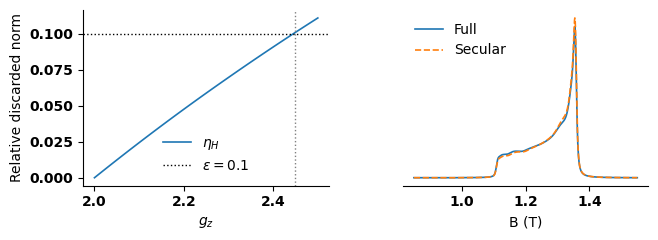

In [5]:
def make_1(gz, mesh):
    g = mars.spin_model.Interaction([2.0, 2.0, gz], dtype=dtype)
    spin_system = mars.spin_model.SpinSystem(
        electrons=[1/2],
        g_tensors=[g],
        dtype=dtype
    )
    sample = mars.spin_model.SolidSample(
        base_spin_system=spin_system,
        gauss=5e-3,
        lorentz=5e-3,
        dtype=dtype,
        mesh=mesh,
    )
    return sample


result_1 = run_case("1. S=1/2: axial g anisotropy", make_1,
    np.linspace(2.0, 2.5, 41),
    g_mean=2.0, fields=torch.linspace(0.85, 1.55, n_field_points, dtype=dtype),
    xlabel=r"$g_z$"
)


## 2. $S=5/2$ + $^{55}$Mn: isotropic $g$, varying hyperfine anisotropy

One electron ($S=5/2$) and one $^{55}$Mn nucleus ($I=5/2$). The $g$-tensor is isotropic, $g=(2.1,2.1,2.1)$; ZFS parameters are $D=-100$ MHz and $E=20$ MHz. Set $A_x=A_y=100$ MHz and vary $\Delta A=A_z-A_x$ from 0 to 10,000 MHz. Thus $A=(100,100,100+\Delta A)$ MHz, with isotropic hyperfine coupling at $\Delta A=0$ and $A=(100,100,1000)$ MHz at $\Delta A=900$ MHz. Gaussian and Lorentzian linewidths: 5 mT each.

1.2928637789973108
2. S=5/2 + 55Mn: isotropic g: first failure in [2.7e+03, 2.78e+03].
B0=1.293 T; eta_F=0.787; eta_Gz=1.06e-16; eta_H=0.101; maximum level shift=5.14e+03 MHz


D:\ITC\РНФ_Курганский_2024\pythonProject\MarS\mars\spectra_manager\res_line_solvers\res_field_algorithm.py:631: UserWarning: Near-degenerate energy levels were detected in this spin system. Resonance-field results may require additional convergence checks.
Increase the orientation mesh density; for spherical powder integration, consider increasing opt.integration_level. Tighten the resonance-field tolerance by decreasing opt.res_field_r_tol (a larger value is less accurate), and increase opt.res_field_split_max_iterations if necessary.
For time-resolved EPR, the rotating-wave approximation (RWA) may be unreliable because secularization can become invalid near degenerate levels. Prefer the kinetic-rate approach (CoupledTimeSpectra) or the direct propagator approach (DensityTimeSpectra with populator='propagator' and hamiltonian_mode='direct'). Alternatively, compare CW spectra with and without secularization (hamiltonian_mode='direct' versus 'secular').
  derivatives_mid = self._compute

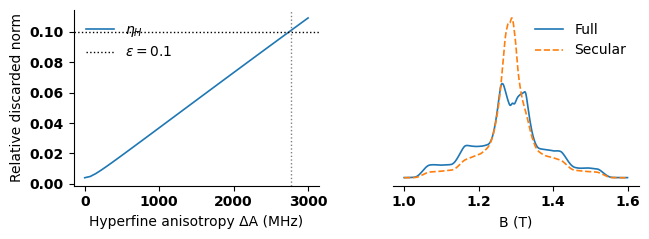

In [6]:
def make_2(delta_A, mesh):
    g = mars.spin_model.Interaction([2.1, 2.1, 2.1], dtype=dtype)
    A = mars.spin_model.Interaction([100e6, 100e6, 100e6 + delta_A], dtype=dtype)
    DE = mars.spin_model.DEInteraction([-100e6, 20e6], dtype=dtype)
    spin_system = mars.spin_model.SpinSystem(
        electrons=[5/2], nuclei=["55Mn"], g_tensors=[g],
        electron_nuclei=[(0, 0, A)], electron_electron=[(0, 0, DE)], dtype=dtype)
    sample = mars.spin_model.SolidSample(
        base_spin_system=spin_system, gauss=5e-3, lorentz=5e-3, dtype=dtype, mesh=mesh)
    return sample

result_2 = run_case("2. S=5/2 + 55Mn: isotropic g", make_2,
                    np.linspace(0, 3000e6, 41), g_mean=2.1,
                    fields=torch.linspace(1.0, 1.6, n_field_points, dtype=dtype),
                    xlabel="Hyperfine anisotropy ΔA (MHz)", units=1e6)

## 3. $S=5/2$ + $^{55}$Mn: anisotropic $g$, varying hyperfine anisotropy

Same Mn system as example 2, but with anisotropic $g=(2.0,2.1,2.2)$. Both examples have $D=-100$ MHz, $E=20$ MHz, and $A=(100,100,100+\Delta A)$ MHz. Vary $\Delta A=0$–$10{,}000$ MHz to compare the effect of $g$-anisotropy on the same hyperfine-anisotropy sweep. Gaussian and Lorentzian linewidths: 5 mT each.

1.2928637789973108
3. S=5/2 + 55Mn: anisotropic g: no failure; spectrum at endpoint 600.
B0=1.293 T; eta_F=0.692; eta_Gz=0.0474; eta_H=0.052; maximum level shift=1.02e+03 MHz


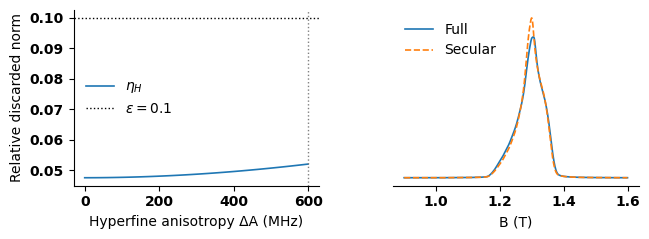

In [7]:
def make_3(delta_A, mesh):
    g = mars.spin_model.Interaction([2.0, 2.1, 2.2], dtype=dtype)
    A = mars.spin_model.Interaction([100e6, 100e6, 100e6 + delta_A], dtype=dtype)
    DE = mars.spin_model.DEInteraction([-100e6, 20e6], dtype=dtype)
    spin_system = mars.spin_model.SpinSystem(
        electrons=[5/2], nuclei=["55Mn"], g_tensors=[g],
        electron_nuclei=[(0, 0, A)], electron_electron=[(0, 0, DE)], dtype=dtype)
    sample = mars.spin_model.SolidSample(
        base_spin_system=spin_system, gauss=5e-3, lorentz=5e-3, dtype=dtype, mesh=mesh)
    return sample

result_3 = run_case("3. S=5/2 + 55Mn: anisotropic g", make_3,
                    np.linspace(0, 600e6, 41), g_mean=2.1,
                    fields=torch.linspace(0.9, 1.6, n_field_points, dtype=dtype),
                    xlabel="Hyperfine anisotropy ΔA (MHz)", units=1e6)

## 4. $S=3/2$: isotropic $g$, varying zero-field splitting

One electron with $S=3/2$ and isotropic $g=(2.087,2.087,2.087)$, using the exact mean $(2.0+2.06+2.2)/3$. Vary $D=0$–$12{,}000$ MHz and set $E=0.2D$, so both axial and rhombic ZFS are included with $E/D=0.2$ for $D>0$. Gaussian and Lorentzian linewidths: 5 mT each.

1.301124889406239
4. S=3/2: isotropic g: no failure; spectrum at endpoint 4e+03.
B0=1.301 T; eta_F=1; eta_Gz=1.1e-16; eta_H=0.0991; maximum level shift=460 MHz


D:\ITC\РНФ_Курганский_2024\pythonProject\MarS\mars\spin_model.py:3324: UserWarning: MaRs secular approximation validity check failed.

The combined static Hamiltonian H = F + B * Gz was checked  H: discarded relative norm = 0.129
  Allowed maximum = 0.1
The secular projection removes more than the allowed fraction of the complete static Hamiltonian. The separate F and Gz ratios are diagnostic only and do not determine validity at this field.

The approximation may affect energy levels, transition frequencies, intensities, and relaxation dynamics. Passing this norm test does not guarantee spectral accuracy. Consider using hamiltonian_mode='direct' for comparison, or adjusting the secular settings.
  self._check_secularity(


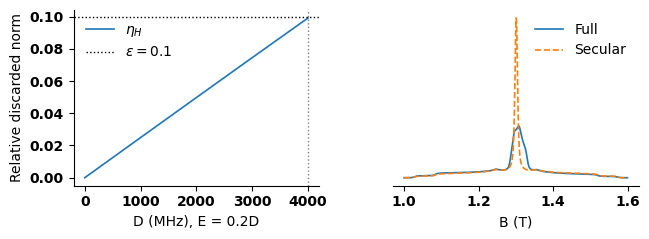

In [8]:
def make_4(D, mesh):
    g_mean = float(np.mean([2.0, 2.06, 2.2]))
    g = mars.spin_model.Interaction(g_mean, dtype=dtype)
    DE = mars.spin_model.DEInteraction([D, 0.2 * D], dtype=dtype)
    spin_system = mars.spin_model.SpinSystem(
        electrons=[3/2], g_tensors=[g],
        electron_electron=[(0, 0, DE)], dtype=dtype)
    sample = mars.spin_model.SolidSample(
        base_spin_system=spin_system, gauss=5e-3, lorentz=5e-3, dtype=dtype, mesh=mesh)
    return sample

result_4 = run_case("4. S=3/2: isotropic g", make_4,
                    np.linspace(0, 4000e6, 41), g_mean=np.mean([2.0, 2.06, 2.2]),
                    fields=torch.linspace(1.0, 1.6, n_field_points, dtype=dtype),
                    xlabel="D (MHz), E = 0.2D", units=1e6)

## 5. $S=3/2$: anisotropic $g$, varying zero-field splitting

Same $S=3/2$ system as example 4, but with anisotropic $g=(2.0,2.06,2.2)$. Vary the same $D=0$–$12{,}000$ MHz, with $E=0.2D$; the $g$-tensor is the only difference between examples 4 and 5. Gaussian and Lorentzian linewidths: 5 mT each.

1.301124889406239
5. S=3/2: anisotropic g: no failure; spectrum at endpoint 1.5e+03.
B0=1.301 T; eta_F=1; eta_Gz=0.0474; eta_H=0.0587; maximum level shift=189 MHz


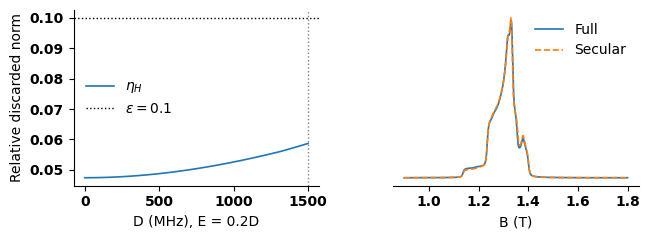

In [9]:
def make_5(D, mesh):
    g = mars.spin_model.Interaction([2.0, 2.06, 2.2], dtype=dtype)
    DE = mars.spin_model.DEInteraction([D, 0.2 * D], dtype=dtype)
    spin_system = mars.spin_model.SpinSystem(
        electrons=[3/2], g_tensors=[g],
        electron_electron=[(0, 0, DE)], dtype=dtype)
    sample = mars.spin_model.SolidSample(
        base_spin_system=spin_system, gauss=5e-3, lorentz=5e-3, dtype=dtype, mesh=mesh)
    return sample

result_5 = run_case("5. S=3/2: anisotropic g", make_5,
                    np.linspace(0, 1500e6, 41), g_mean=np.mean([2.0, 2.06, 2.2]),
                    fields=torch.linspace(0.9, 1.8, n_field_points, dtype=dtype),
                    xlabel="D (MHz), E = 0.2D", units=1e6)

## 6. Two $S=1/2$ electrons: dipolar coupling

Two $S=1/2$ electrons with isotropic tensors $g_1=2.00$ and $g_2=2.25$. Their dipolar interaction is axial ($E_{12}=0$); vary $D_{12}=0$–$15000$ MHz. Gaussian and Lorentzian linewidths: 2 mT each.

1.27765361689146
6. Two S=1/2 electrons: dipolar coupling: no failure; spectrum at endpoint 1e+04.
B0=1.278 T; eta_F=1; eta_Gz=1.65e-16; eta_H=0.0756; maximum level shift=113 MHz


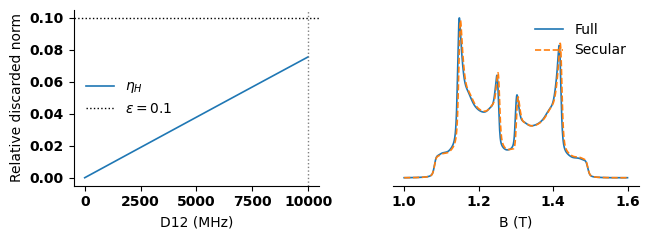

In [10]:
def make_6(D12, mesh):
    g1 = mars.spin_model.Interaction(2.00, dtype=dtype)
    g2 = mars.spin_model.Interaction(2.25, dtype=dtype)
    dipolar = mars.spin_model.DEInteraction([D12, 0.0], dtype=dtype)
    spin_system = mars.spin_model.SpinSystem(
        electrons=[1/2, 1/2], g_tensors=[g1, g2],
        electron_electron=[(0, 1, dipolar)], dtype=dtype)
    sample = mars.spin_model.SolidSample(
        base_spin_system=spin_system, gauss=5e-3, lorentz=5e-3, dtype=dtype, mesh=mesh)
    return sample

result_6 = run_case("6. Two S=1/2 electrons: dipolar coupling", make_6,
                    np.linspace(0, 10000e6, 31), g_mean=2.125,
                    fields=torch.linspace(1.0, 1.6, n_field_points, dtype=dtype),
                    xlabel="D12 (MHz)", units=1e6)